# Pendahuluan

Di dalam material ini, kamu akan mempelajari Data Heart Disease dan belajar bagaimana melakukan pemodelan. Lakukan kode dan jalankan setiap sel. Selama proses pembelajaran, kamu akan menemui beberapa blok -- ikuti petunjuk untuk mengisinya sebelum menjalankan sel-sel tersebut dan melanjutkan.

In [89]:
# Tahapan sebelumnya
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

# Memuat dataset yang sudah rapi ditahapan sebelumnya
data = "data.csv"
df = pd.read_csv(data, index_col=0)
df['sex'] = df['sex'].replace({'Male' : 1,'Female': 0})
df['cp'] = df['cp'].replace({'typical angina' : 0, 'atypical angina' : 1, 'non-anginal pain' : 2, 'asymtomatic' : 3})
df['fbs'] = df['fbs'].replace({'No' : 0, 'Yes' : 1})
df['restecg'] = df['restecg'].replace({'probable or definite left ventricular hypertrophy':0,'normal':1,'ST-T Wave abnormal':2})
df['exang'] = df['exang'].replace({'No':0,'Yes':1})
df['slope'] = df['slope'].replace({'downsloping':0, 'flat':1,'upsloping':2})
df['thal'] = df['thal'].replace({'normal':1, 'fixed defect':2,'reversable defect':3})
df['ca'] = df['ca'].replace({'Number of major vessels: 0':0, 'Number of major vessels: 1':1,'Number of major vessels: 2':2, 'Number of major vessels: 3':3})
df['target'] = df['target'].replace({'No disease':0,'Disease':1})

'''TODO: Ambil variabel terpilih'''
# Variabel terpilih
df = df[['cp', 'thalach', 'slope', 'oldpeak', 'exang', 'ca', 'thal', 'sex', 'age', 'target']]


In [90]:
# Liat informasi dari dataset yang kita miliki
print(df.head())
print(df.columns)


  cp  thalach slope  oldpeak exang ca thal sex  age target
0  0      168     2      1.0     0  2    3   1   52      0
1  0      155     0      3.1     1  0    3   1   53      0
2  0      125     0      2.6     1  0    3   1   70      0
3  0      161     2      0.0     0  1    3   1   61      0
4  0      106     1      1.9     0  3    2   0   62      0
Index(['cp', 'thalach', 'slope', 'oldpeak', 'exang', 'ca', 'thal', 'sex',
       'age', 'target'],
      dtype='str')


**Memisahkan variabel dependen dan independen**

Variabel dependen yang digunakan adalah data pada kolom 'target', kolom feature merupakan variabel independen. Disini kamu akan membuat variabel X menggunakan .isin() untuk semua kolom kecuali kolom target, kemudian variabel y yang hanya kolom target saja.

In [91]:
# Define X and y
X = df[df.columns[~df.columns.isin(['target'])]]
y = df['target'].astype(int) 


In [92]:
# Melihat kolom yang termasuk variable indepnden
X.head()

,cp,thalach,slope,oldpeak,exang,ca,thal,sex,age
0,0,168,2,1.0,0,2,3,1,52
1,0,155,0,3.1,1,0,3,1,53
2,0,125,0,2.6,1,0,3,1,70
3,0,161,2,0.0,0,1,3,1,61
4,0,106,1,1.9,0,3,2,0,62


In [93]:
# Melihat variabel dependen
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [94]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


**Spliting data**

Pisahkan dataset menjadi training dan testing dataset dengan perbandingan 80:20 dan random state 42!

In [95]:
# Mendefinisikan pemisahan data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Menampilkan hasil pemisahan berdasarkan kolom dan baris
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(226, 9)
(57, 9)
(226,)
(57,)


**Pemodelan dengan Heart Disease Dataset**

saya akan melakukan pemodelan untuk 4 model berbeda diantaranya logistic regression, decision tree, random forest dan neural networks.

In [96]:
print(y_train.dtype)
print(y_train.shape)
print(y_train.unique())      # kalau y_train berupa Series
print(y_train.isna().sum())  # cek ada NaN atau tidak

int64
(226,)
[0 1]
0


In [97]:
# Menyiapkan libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [98]:
clf = LogisticRegression(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Logistric Regression Classifier is ", accuracy_score(y_test, y_pred))


The test accuracy score of Logistric Regression Classifier is  0.8421052631578947


In [99]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.81      0.82        26
           1       0.84      0.87      0.86        31

    accuracy                           0.84        57
   macro avg       0.84      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



In [100]:
clf = DecisionTreeClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Decision Tree Classifier is ", accuracy_score(y_test, y_pred))


The test accuracy score of Decision Tree Classifier is  0.7192982456140351


In [101]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.73      0.70        26
           1       0.76      0.71      0.73        31

    accuracy                           0.72        57
   macro avg       0.72      0.72      0.72        57
weighted avg       0.72      0.72      0.72        57



In [102]:
clf = RandomForestClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Random Forest Classifier is ", accuracy_score(y_test, y_pred))


The test accuracy score of Random Forest Classifier is  0.8245614035087719


In [103]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.77      0.80        26
           1       0.82      0.87      0.84        31

    accuracy                           0.82        57
   macro avg       0.83      0.82      0.82        57
weighted avg       0.83      0.82      0.82        57



In [104]:
clf = MLPClassifier(random_state=42, max_iter=1000)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of MLP Classifier is ", accuracy_score(y_test, y_pred))


The test accuracy score of MLP Classifier is  0.7894736842105263


In [105]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.73      0.76        26
           1       0.79      0.84      0.81        31

    accuracy                           0.79        57
   macro avg       0.79      0.78      0.79        57
weighted avg       0.79      0.79      0.79        57



**Membandingkan hasil diatas**

Berdasarkan hasil ke-4 model (Random Forest, Logistic Regression, Decision Tree dan Multi-layer Perceptron). Berikut didapatkan akurasi pada proses kali ini:
- Pada model Decision Tree memiliki nilai akurasi terkecil sebesar 72% dengan recall sebesar 72%.
- Random Forest memiliki nilai akurasi terbesar sebesar 82% dengan recall 82%

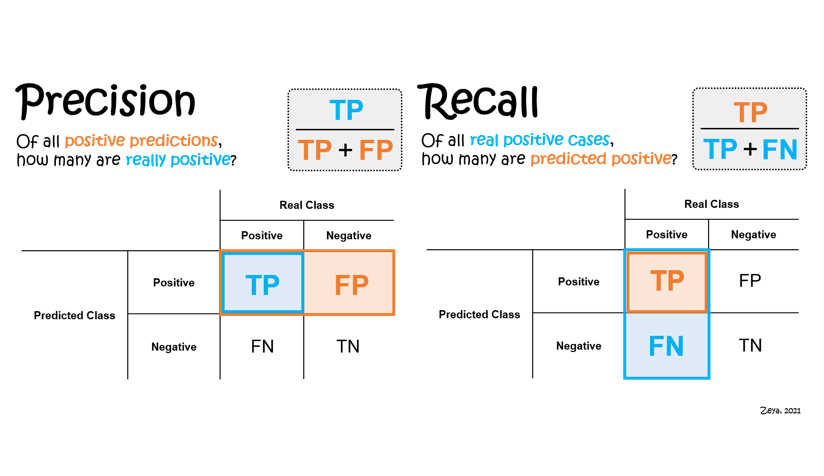

**Pojok Catatan**

Recall: Kemampuan model untuk menemukan semua kasus relevan dimana kebanyakan penting untuk deteksi risiko tinggi (seperti deteksi kanker), recall adalah metrik evaluasi yang lebih penting daripada presisi.

Dalam kasus prediksi gagal jantung, kita ingin menghindari false negatives sebanyak mungkin. Kasus false negative berarti masalah gagal jantung tidak terdeteksi, yang bisa sangat berbahaya. Dalam kasus penggunaan ini, false positives (seseorang yang sehat dengan diagnosis masalah jantung tidak sehat) tidak sepenting mencegah situasi ketika kita tidak mendeteksi masalah serius.

**Proses Hyperparameter Tuning**

In [106]:
# Logistic regression classifier with hyperparameter
clf = LogisticRegression(random_state=42)
param_grid = {
    'max_iter': [100, 200, 500],
    'solver': ['lbfgs', 'liblinear', 'saga']
}
gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )
fit_clf_lg = gs1.fit(X_train, y_train)
print(fit_clf_lg.best_params_)
print(fit_clf_lg.best_score_)


{'max_iter': 100, 'solver': 'liblinear'}
0.9209805668016194


In [107]:
y_pred = fit_clf_lg.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.84      0.81      0.82        26
           1       0.84      0.87      0.86        31

    accuracy                           0.84        57
   macro avg       0.84      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



Setelah dilakukan hyperparameter tuning model logistic regression tidak terjadi peningkatan pada nilai akurasi. Nilai akurasi tetap 84%.

In [108]:
# Random Forest classifier with hyperparameter
clf = RandomForestClassifier(random_state=42)
param_grid = {'n_estimators': [50, 100, 200],
               'max_depth': [None, 5, 10],
               'criterion': ['gini', 'entropy']}
gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )
fit_clf_rf = gs1.fit(X_train, y_train)
print(fit_clf_rf.best_params_)
print(fit_clf_rf.best_score_)


{'criterion': 'entropy', 'max_depth': 5, 'n_estimators': 100}
0.910851012145749


In [109]:
y_pred = fit_clf_rf.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.87      0.77      0.82        26
           1       0.82      0.90      0.86        31

    accuracy                           0.84        57
   macro avg       0.85      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



Setelah dilakukan model random forest dilakukan hyperparameter tuning akurasi model menaik menjadi 84% dari yang awalnya 82%. 

In [110]:
# Decision Tree classifier with hyperparameter
clf = DecisionTreeClassifier(random_state=42)
param_grid = {'min_samples_leaf': [1, 2, 5, 10],
               'max_depth': [None, 5, 10, 20],
               'criterion': ['gini', 'entropy']}
gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )
fit_clf_dt = gs1.fit(X_train, y_train)
print(fit_clf_dt.best_params_)
print(fit_clf_dt.best_score_)


{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 10}
0.8856931174089068


In [111]:
y_pred = fit_clf_dt.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.83      0.73      0.78        26
           1       0.79      0.87      0.83        31

    accuracy                           0.81        57
   macro avg       0.81      0.80      0.80        57
weighted avg       0.81      0.81      0.81        57



Setelah dilakukan hyperparameter tuning model decision tree terjadi peningkatan pada nilai akurasi walaupun lumayan signifikan. Nilai akurasi naik dari yang awalnya 71% menjadi 81%.

In [112]:
# MLP Classifier with hyperparameter
clf = MLPClassifier(random_state=42)
param_grid1 = {'hidden_layer_sizes': [(50,), (100,), (100, 50)],
               'activation': ['relu', 'tanh'],
               'solver': ['adam', 'sgd']}
gs1 = GridSearchCV(
        estimator=clf,
        param_grid=param_grid1,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )
fit_clf_mlp = gs1.fit(X_train, y_train)
print(fit_clf_mlp.best_params_)
print(fit_clf_mlp.best_score_)


{'activation': 'tanh', 'hidden_layer_sizes': (100, 50), 'solver': 'sgd'}
0.9289028340080971


In [113]:
y_pred = fit_clf_mlp.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.81      0.81      0.81        26
           1       0.84      0.84      0.84        31

    accuracy                           0.82        57
   macro avg       0.82      0.82      0.82        57
weighted avg       0.82      0.82      0.82        57



Setelah dilakukan model random forest dilakukan hyperparameter tuning akurasi model menaik menjadi 82% dari yang awalnya 79%.

**ROC Analysis**

Kurva yang menyajikan ilustrasi performansi dari binary classifier system dalam menghasilkan sebuah prediksi

In [114]:

# Predict the probabilities for the positive class
y_pred_logreg = fit_clf_lg.predict_proba(X_test)[:, 1]
y_pred_rf = fit_clf_rf.predict_proba(X_test)[:, 1]
y_pred_dt = fit_clf_dt.predict_proba(X_test)[:, 1]
y_pred_mlp = fit_clf_mlp.predict_proba(X_test)[:, 1]
# Calculate the AUC-ROC scores
auc_logreg = roc_auc_score(y_test, y_pred_logreg)
auc_rf = roc_auc_score(y_test, y_pred_rf)
auc_dt = roc_auc_score(y_test, y_pred_dt)
auc_mlp = roc_auc_score(y_test, y_pred_mlp)
print(f"AUC-ROC for Logistic Regression: {auc_logreg}")
print(f"AUC-ROC for Random Forest: {auc_rf}")
print(f"AUC-ROC for Decision Tree: {auc_dt}")
print(f"AUC-ROC for MLP: {auc_mlp}")


AUC-ROC for Logistic Regression: 0.879652605459057
AUC-ROC for Random Forest: 0.9007444168734492
AUC-ROC for Decision Tree: 0.8411910669975187
AUC-ROC for MLP: 0.8771712158808933


Jika dilihat dari nilai AUC-ROC, model Random Forest memiliki nilai yang paling tinggi. Akan tetapi perbedaan nilai AUC-ROC Random Forest dengan 1 model lainnya tidak terpaut jauh dengan logistic regression.

ROC adalah kurva probabilitas dan AUC mewakili tingkat atau ukuran pemisahan. Ini menunjukkan seberapa baik model mampu membedakan antara kelas. Semakin tinggi AUC, semakin baik modelnya dalam memprediksi kelas 0 sebagai 0 dan kelas 1 sebagai 1.

Kurva ROC digambarkan dengan TPR (True Positive Rate) melawan FPR (False Positive Rate) di mana TPR berada di sumbu y dan FPR berada di sumbu x.

Model yang sangat baik memiliki AUC mendekati 1, yang berarti memiliki ukuran pemisahan yang baik. Model yang buruk memiliki AUC mendekati 0, yang berarti memiliki ukuran pemisahan yang terburuk.

Ketika AUC adalah 0.7, artinya ada peluang sebesar 70% bahwa model akan mampu membedakan antara kelas positif dan kelas negatif. Ketika AUC mendekati 0.5, model tidak memiliki kemampuan diskriminasi untuk membedakan antara kelas positif dan kelas negatif. Ketika AUC mendekati 0, model memprediksi kelas negatif sebagai kelas positif dan sebaliknya.

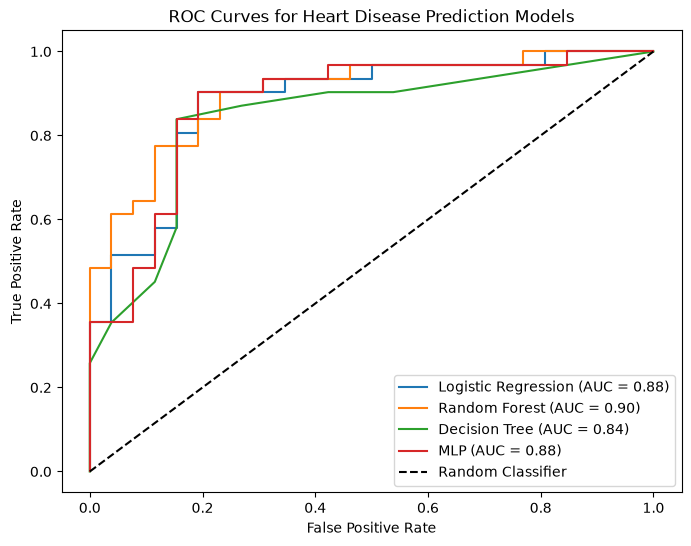

In [115]:
#Membuat ROC Analisis
def plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp):
    plt.figure(figsize=(8, 6))
    # Calculate ROC curves for each model
    fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_logreg)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
    fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
    fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_mlp)
    # Plot ROC curves
    plt.plot(fpr_logreg, tpr_logreg, label=f'Logistic Regression (AUC = {auc_logreg:.2f})')
    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
    plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
    plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')
    # Plot random classifier
    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
    # Format the plot
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Heart Disease Prediction Models')
    plt.legend()
    plt.show()
plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp)


In [ ]:
def find_rates_for_thresholds(y_test, y_pred, thresholds):
    fpr_list = []
    tpr_list = []
    for threshold in thresholds:
        y_pred_binary = (y_pred > threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_binary).ravel()
        fpr = fp / (fp + tn)
        tpr = tp / (tp + fn)
        fpr_list.append(fpr)
        tpr_list.append(tpr)
    return fpr_list, tpr_list

thresholds = np.arange(0, 1.1, 0.1)
fpr_logreg, tpr_logreg = find_rates_for_thresholds(y_test, y_pred_logreg, thresholds)
fpr_rf, tpr_rf = find_rates_for_thresholds(y_test, y_pred_rf, thresholds)
fpr_dt, tpr_dt = find_rates_for_thresholds(y_test, y_pred_dt, thresholds)
fpr_mlp, tpr_mlp = find_rates_for_thresholds(y_test, y_pred_mlp, thresholds)

summary_df = pd.DataFrame({
    'Threshold': thresholds,
    'FPR_LogReg': fpr_logreg,
    'TPR_LogReg': tpr_logreg,
    'FPR_RF': fpr_rf,
    'TPR_RF': tpr_rf,
    'FPR_DT': fpr_dt,
    'TPR_DT': tpr_dt,
    'FPR_MLP': fpr_mlp,
    'TPR_MLP': tpr_mlp
})
print(summary_df)


    Threshold  FPR_LogReg  TPR_LogReg    FPR_RF    TPR_RF    FPR_DT    TPR_DT  \
0         0.0    1.000000    1.000000  1.000000  1.000000  0.538462  0.903226   
1         0.1    0.500000    0.935484  0.730769  0.967742  0.423077  0.903226   
2         0.2    0.346154    0.935484  0.576923  0.967742  0.423077  0.903226   
3         0.3    0.269231    0.903226  0.384615  0.935484  0.269231  0.870968   
4         0.4    0.192308    0.903226  0.307692  0.903226  0.269231  0.870968   
5         0.5    0.192308    0.870968  0.230769  0.903226  0.269231  0.870968   
6         0.6    0.192308    0.838710  0.230769  0.870968  0.153846  0.838710   
7         0.7    0.153846    0.612903  0.115385  0.677419  0.153846  0.580645   
8         0.8    0.115385    0.548387  0.000000  0.483871  0.153846  0.580645   
9         0.9    0.000000    0.322581  0.000000  0.258065  0.153846  0.580645   
10        1.0    0.000000    0.000000  0.000000  0.000000  0.000000  0.000000   

     FPR_MLP   TPR_MLP  
0 

In [117]:
def find_best_threshold(y_test, y_pred):
    # based on Youden's Index
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    optimal_idx = np.argmax(tpr - fpr)
    return thresholds[optimal_idx]

best_threshold_logreg = find_best_threshold(y_test, y_pred_logreg)
best_threshold_rf = find_best_threshold(y_test, y_pred_rf)
best_threshold_dt = find_best_threshold(y_test, y_pred_dt)
best_threshold_mlp = find_best_threshold(y_test, y_pred_mlp)
print(f"Best threshold for Logistic Regression: {best_threshold_logreg}")
print(f"Best threshold for Random Forest: {best_threshold_rf}")
print(f"Best threshold for Decision Tree: {best_threshold_dt}")
print(f"Best threshold for MLP: {best_threshold_mlp}")


Best threshold for Logistic Regression: 0.4246777284072778
Best threshold for Random Forest: 0.5986790151513532
Best threshold for Decision Tree: 0.6111111111111112
Best threshold for MLP: 0.4721780118815394


**Ingat**

1. Jika kita menginginkan model yang memiliki sensitivitas yang tinggi, yaitu kemampuan untuk mendeteksi sebanyak mungkin kasus positif (True Positive), maka lebih baik menggunakan treshold yang lebih rendah. Namun, ini mungkin juga akan menyebabkan peningkatan False Positive Rate (kasus negatif yang salah diprediksi positif).
2. Sebaliknya, jika kita ingin mengurangi kesalahan dalam memprediksi kasus negatif sebagai positif (False Positive), maka kita akan memilih treshold yang lebih tinggi. Namun, ini dapat mengurangi sensitivitas model (menyebabkan lebih banyak True Negative yang salah diprediksi negatif).

Jadi dapat disimpulkan, bahwa model yang peformanya lebih bagus ialah model Random Forest dengan ditandai dengan model Random Forest yang memiliki nilai akurasi pada classification report tertinggi, yaitu sebesar 82% dan Model Random Forest memiliki score AUC-ROC Terbesar dibandingkan 3 model lainnya, yaitu sebesar 90%, namun model ini memiliki treshold yang tinggi dimana akan meningkatkan FPR (Kasus negatif yang salah diprediksi positif).

In [118]:
import pickle
# Menyimpan model terbaik dengan pickle
pklname = "best_model_rf.pkl"
with open(pklname, 'wb') as file:
    pickle.dump(fit_clf_rf, file)
print(f"Model saved as {pklname}")


Model saved as best_model_rf.pkl


Copyright © DQlab Academy x Abel Kristanto